First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  Species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Species:
['setosa' 'versicolor' 'virginica']

Dataset shape:
(150, 5)


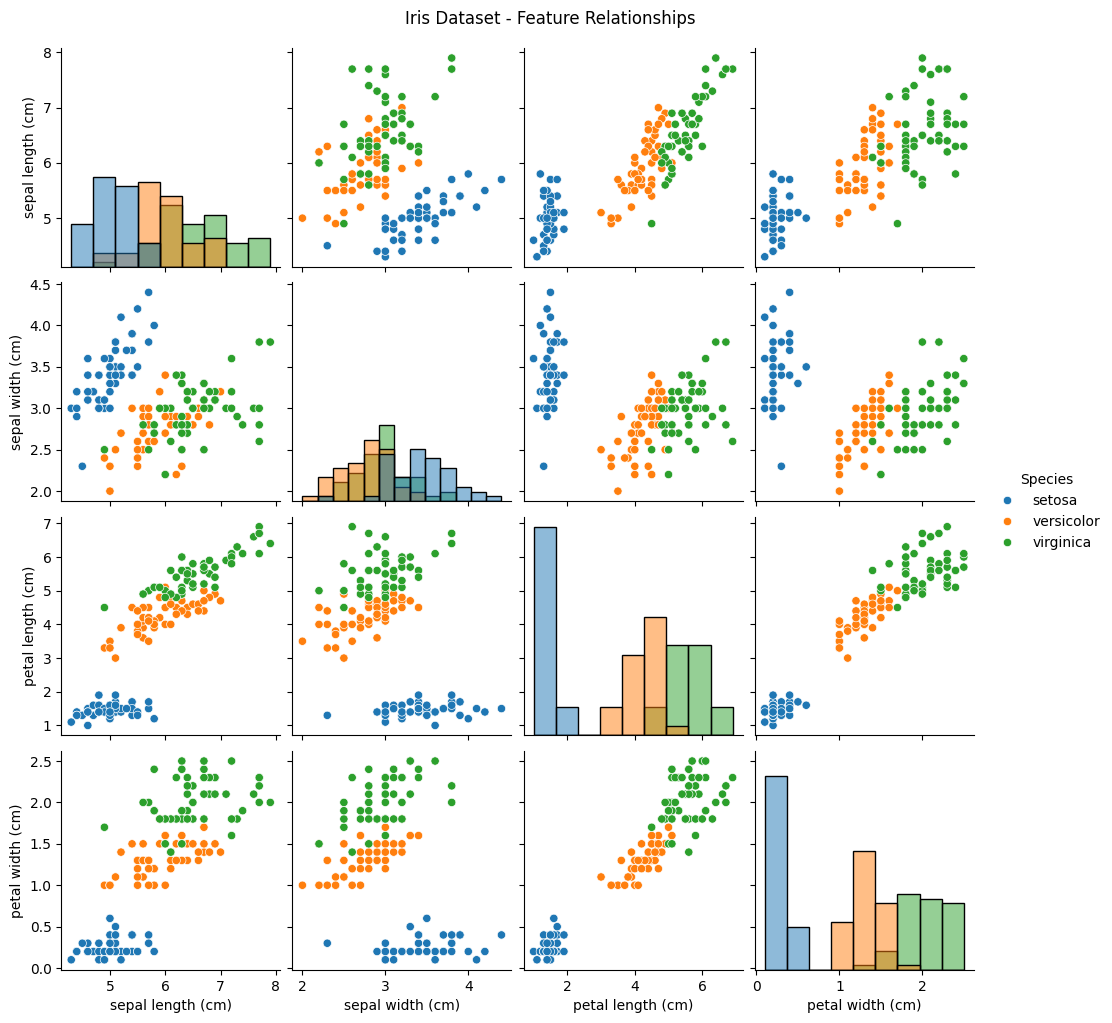

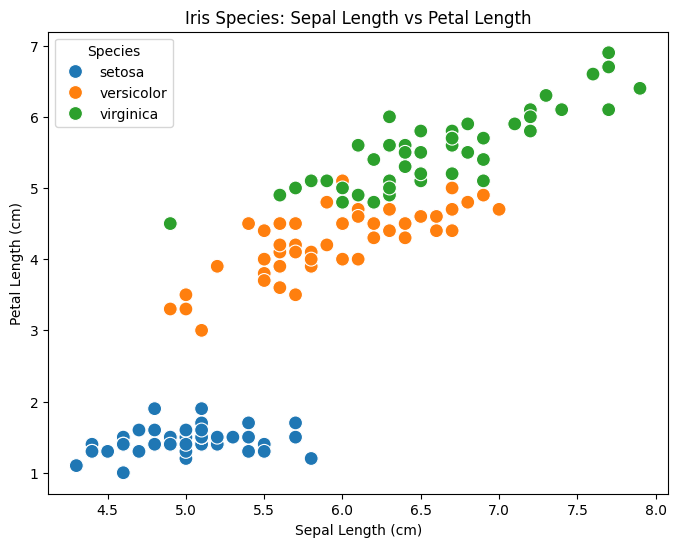

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


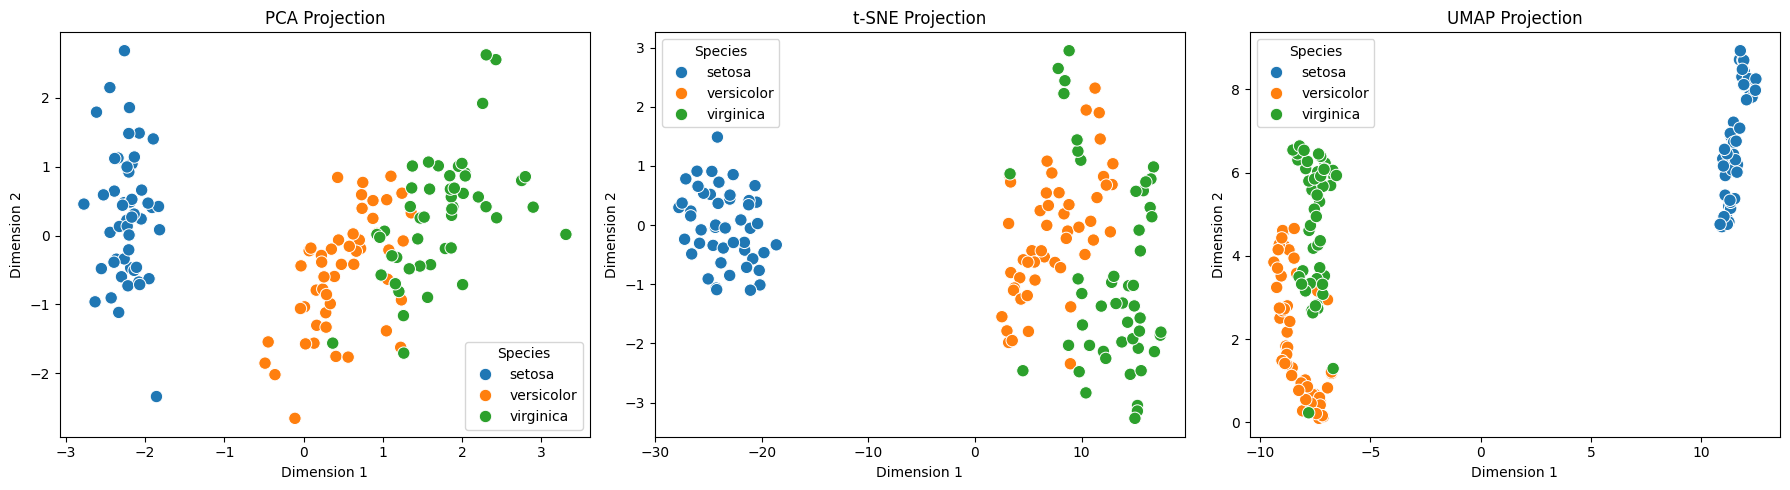

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# iris dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names
df = pd.DataFrame(X, columns=feature_names)

# Add species names
df["Species"] = [target_names[i] for i in y]
print("First 5 rows:")
print(df.head())
print("\nFeatures:")
print(feature_names)
print("\nSpecies:")
print(target_names)
print("\nDataset shape:")
print(df.shape)

# pair plot for species
sns.pairplot(df, hue="Species", diag_kind="hist")
plt.suptitle("Iris Dataset - Feature Relationships", y=1.02)
plt.show()

# plot using 2 features
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="sepal length (cm)",
    y="petal length (cm)",
    hue="Species",
    s=100
)
plt.title("Iris Species: Sepal Length vs Petal Length")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.show()

# standardise
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# pca of 4 to 2
pca = PCA(n_components=2)
pca_res = pca.fit_transform(X_scaled)

# tsne of 4 to 2
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_res = tsne.fit_transform(X_scaled)

# umap of 4 to 2
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    random_state=42
)
umap_res = umap_model.fit_transform(X_scaled)

# data frames
pca_df = pd.DataFrame(
    pca_res,
    columns=["Dimension 1", "Dimension 2"]
)
pca_df["Species"] = df["Species"]

tsne_df = pd.DataFrame(
    tsne_res,
    columns=["Dimension 1", "Dimension 2"]
)
tsne_df["Species"] = df["Species"]

umap_df = pd.DataFrame(
    umap_res,
    columns=["Dimension 1", "Dimension 2"]
)
umap_df["Species"] = df["Species"]

# plot
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

# PCA
sns.scatterplot(
    data=pca_df,
    x="Dimension 1",
    y="Dimension 2",
    hue="Species",
    s=80,
    ax=axes[0]
)
axes[0].set_title("PCA Projection")

# t-SNE
sns.scatterplot(
    data=tsne_df,
    x="Dimension 1",
    y="Dimension 2",
    hue="Species",
    s=80,
    ax=axes[1]
)
axes[1].set_title("t-SNE Projection")

# UMAP
sns.scatterplot(
    data=umap_df,
    x="Dimension 1",
    y="Dimension 2",
    hue="Species",
    s=80,
    ax=axes[2]
)
axes[2].set_title("UMAP Projection")

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


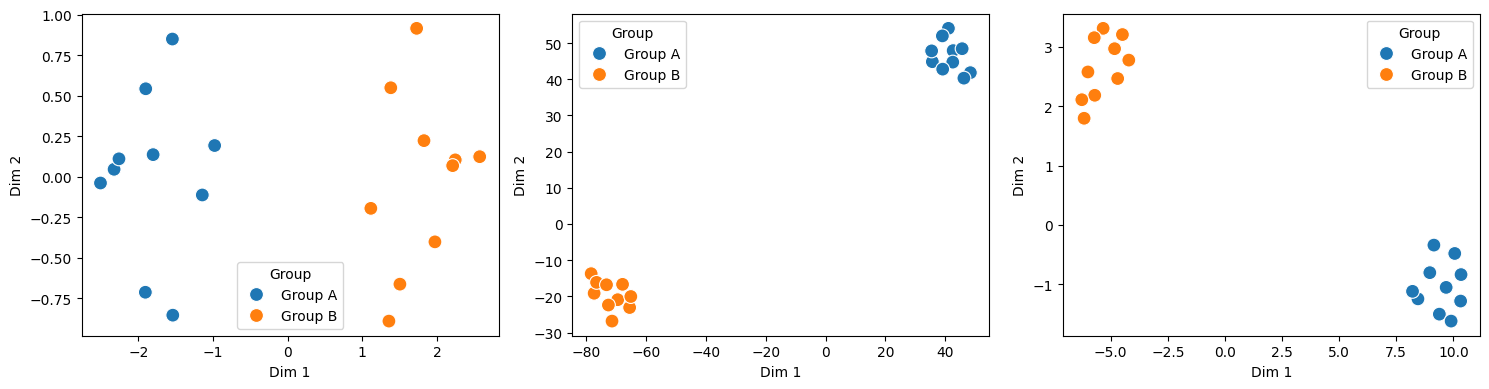

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# --- DATASET GENERATION (Do not change) ---
np.random.seed(42)
data = np.random.randn(20, 4)
data[10:, :] += 3.5 # Create 2 groups
labels = ['Group A']*10 + ['Group B']*10
df = pd.DataFrame(data, columns=['F1', 'F2', 'F3', 'F4'])

# X_scaled = df.values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# PCA
pca_res = PCA(n_components=2).fit_transform(X_scaled)

# tsne_res = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_scaled)
tsne_res = TSNE(n_components=2, perplexity=5, random_state=42).fit_transform(X_scaled)

# UMAP
umap_res = umap.UMAP(n_components=2, n_neighbors=5,
random_state=42).fit_transform(X_scaled)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
results = [('PCA', pca_res), ('t-SNE', tsne_res), ('UMAP', umap_res)]

# for ax, (title, res_data) in zip(axes, results):
  # plot_df = pd.DataFrame(res_data, columns=['Dim 1', 'Dim 2'])
  # sns.scatterplot(data=plot_df, x='Dim 1', y='Dim 2', ax=ax, s=100)
  # ax.set_title(f"{title} Projection")

for ax, (title, res_data) in zip(axes, results):

  plot_df = pd.DataFrame(
      res_data,
      columns=['Dim 1', 'Dim 2']
  )

  plot_df['Group'] = labels

  sns.scatterplot(
      data=plot_df,
      x='Dim 1',
      y='Dim 2',
      hue='Group',
      ax=ax,
      s=100
  )
plt.tight_layout()
plt.show()